In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-FCD/data.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-FCD/lock.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-SCD/data.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-SCD/lock.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TestingSet/data.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TestingSet/lock.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TrainingSet/data.mdb
/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TrainingSet/lock.mdb


/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/sroie_test_1011.json
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/sroie_train_1011.json
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X00016469670.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X00016469671.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005200931.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005230605.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005230616.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005230621.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005230648.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005230657.jpg
/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie/test/X51005230659.jpg
/kaggle/input/datasets/kylianronfleuxcorail/

In [2]:
!pip install lmdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/572.1 kB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 8.9 MB/s  0:00:00


In [3]:
import lmdb
import pickle
import numpy as np
import cv2

# Path to one of the LMDB folders in the dataset
lmdb_path = "/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-FCD"

# Open LMDB in read-only mode
env = lmdb.open(lmdb_path, readonly=True, lock=False, readahead=False, meminit=False)

with env.begin(write=False) as txn:
    # Get database cursor
    cursor = txn.cursor()
    
    # Grab the total number of entries
    num_samples = txn.stat()['entries']
    print(f"Total entries in LMDB: {num_samples}")
    
    # Iterate through the first 5 keys and inspect values
    for i, (key, value) in enumerate(cursor):
        if i >= 5:
            break
        print(f"Key {i}: {key.decode('utf-8', errors='ignore')}")
        print(f"Value size (bytes): {len(value)}")

Total entries in LMDB: 4001


Key 0: image-000000000
Value size (bytes): 224013
Key 1: image-000000001
Value size (bytes): 247405
Key 2: image-000000002
Value size (bytes): 218559
Key 3: image-000000003
Value size (bytes): 232631
Key 4: image-000000004
Value size (bytes): 235806


In [4]:
import lmdb
import numpy as np
import cv2
import pickle

lmdb_path = "/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TrainingSet"
env = lmdb.open(lmdb_path, readonly=True, lock=False)

with env.begin(write=False) as txn:
    # Get the first sample value
    val_bytes = txn.get(b"image-000000000")
    print("Byte length:", len(val_bytes))
    
    # Check if it's a raw image or pickled object
    try:
        data = pickle.loads(val_bytes)
        print("Successfully unpickled! Type:", type(data))
    except Exception:
        print("Not a pickle object. Trying to decode as raw image bytes...")
        img = cv2.imdecode(np.frombuffer(val_bytes, np.uint8), cv2.IMREAD_COLOR)
        if img is not None:
            print(f"Successfully decoded raw image! Shape: {img.shape}")
        else:
            print("Failed to decode as raw image.")
env.close()

Byte length: 148219
Not a pickle object. Trying to decode as raw image bytes...
Successfully decoded raw image! Shape: (512, 512, 3)


In [5]:
import lmdb

path = "/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TrainingSet"
env = lmdb.open(path, readonly=True, lock=False, readahead=False, meminit=False)

with env.begin(write=False) as txn:
    print("entries:", txn.stat()["entries"])
    for i, (k, v) in enumerate(txn.cursor()):
        print(k, len(v))
        if i >= 9:
            break

env.close()

entries: 240001
b'image-000000000' 148219
b'image-000000001' 168406
b'image-000000002' 101200
b'image-000000003' 179738
b'image-000000004' 175487
b'image-000000005' 169659
b'image-000000006' 105661
b'image-000000007' 143109
b'image-000000008' 143043
b'image-000000009' 107723


samples: 120000


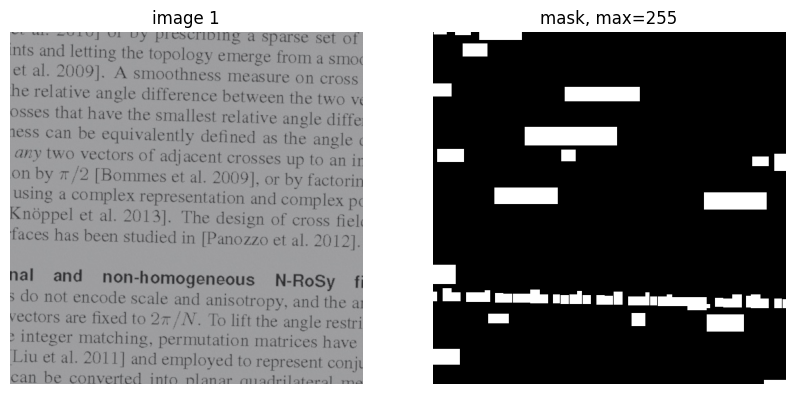

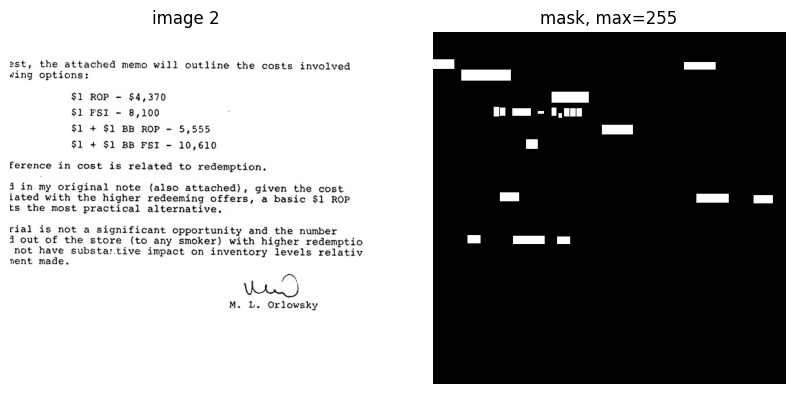

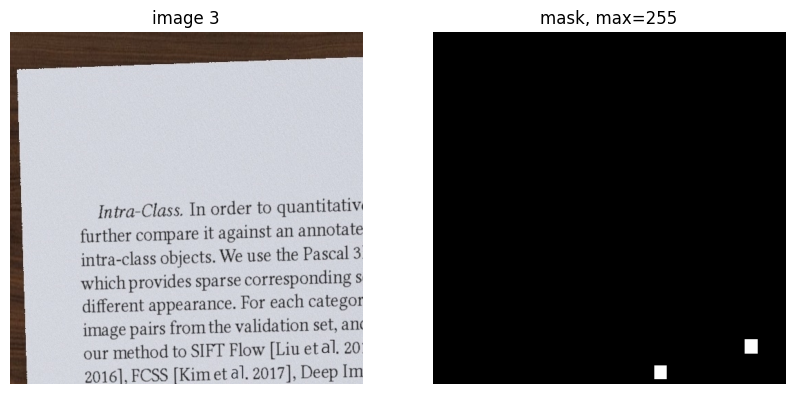

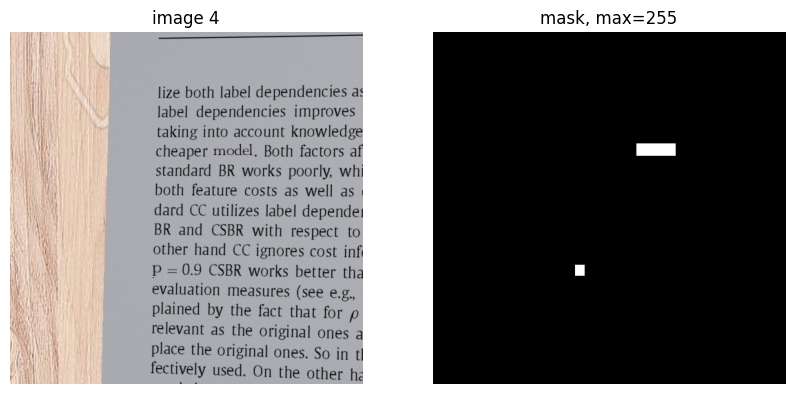

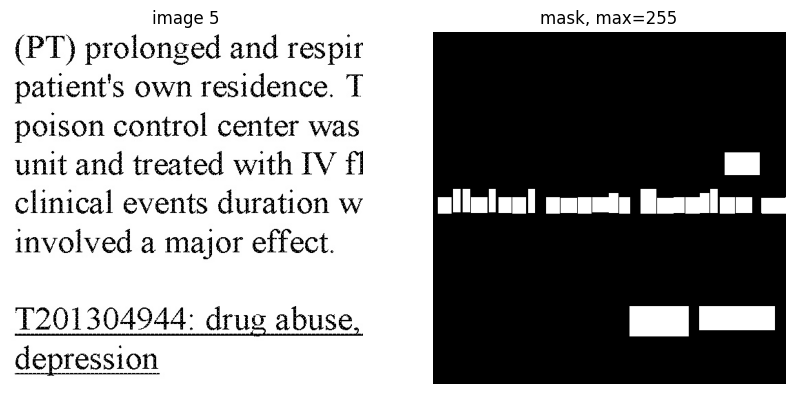

In [6]:
import lmdb, numpy as np, cv2, matplotlib.pyplot as plt

path = "/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TrainingSet"
env = lmdb.open(path, readonly=True, lock=False, readahead=False, meminit=False)

with env.begin(write=False) as txn:
    n = int(txn.get(b"num-samples"))
    print("samples:", n)
    for i in range(1, 6):
        img_b = txn.get(f"image-{i:09d}".encode())
        lbl_b = txn.get(f"label-{i:09d}".encode())
        img = cv2.cvtColor(cv2.imdecode(np.frombuffer(img_b, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        msk = cv2.imdecode(np.frombuffer(lbl_b, np.uint8), cv2.IMREAD_GRAYSCALE)

        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        ax[0].imshow(img); ax[0].set_title(f"image {i}"); ax[0].axis("off")
        ax[1].imshow(msk, cmap="gray"); ax[1].set_title(f"mask, max={msk.max()}"); ax[1].axis("off")
        plt.show()

env.close()

In [7]:
import lmdb
import numpy as np
import cv2

path = "/kaggle/input/datasets/dinmkeljiame/doctamper/DocTamperV1-TrainingSet"
env = lmdb.open(path, readonly=True, lock=False, readahead=False, meminit=False)

with env.begin(write=False) as txn:
    n = int(txn.get(b"num-samples"))
    print(f"Total samples in split: {n}")
    
    # Let's sample a subset (e.g., first 1000 or all if fast) to calculate statistics
    sample_limit = min(1000, n)
    completely_black_masks = 0
    tampered_pixel_fractions = []
    
    for i in range(1, sample_limit + 1):
        lbl_b = txn.get(f"label-{i:09d}".encode())
        if lbl_b is None:
            continue
            
        msk = cv2.imdecode(np.frombuffer(lbl_b, np.uint8), cv2.IMREAD_GRAYSCALE)
        
        # Check if entirely pristine (all pixels == 0)
        if np.all(msk == 0):
            completely_black_masks += 1
        else:
            # Calculate fraction of tampered pixels (pixels > 0)
            fraction = np.sum(msk > 0) / msk.size
            tampered_pixel_fractions.append(fraction)

env.close()

# Print out your Week 1 statistical report
pristine_ratio = completely_black_masks / sample_limit
mean_tampered_share = np.mean(tampered_pixel_fractions) if tampered_pixel_fractions else 0.0

print("\n=== WEEK 1 DATASET STATISTICS REPORT ===")
print(f"Samples Checked: {sample_limit}")
print(f"Pristine Mask Ratio (Entirely Black): {pristine_ratio * 100:.2f}%")
print(f"Mean Tampered Pixel Share (in edited docs): {mean_tampered_share * 100:.4f}%")

Total samples in split: 120000



=== WEEK 1 DATASET STATISTICS REPORT ===
Samples Checked: 1000
Pristine Mask Ratio (Entirely Black): 0.00%
Mean Tampered Pixel Share (in edited docs): 1.8597%


In [8]:
import lmdb, io, random, numpy as np, cv2
from collections import Counter
from PIL import Image

BASE = "/kaggle/input/datasets/dinmkeljiame/doctamper/"
SPLITS = ["DocTamperV1-TrainingSet", "DocTamperV1-TestingSet", "DocTamperV1-FCD", "DocTamperV1-SCD"]

def survey(split, n_sample=2000, seed=0):
    env = lmdb.open(BASE + split, readonly=True, lock=False, readahead=False, meminit=False)
    s = dict(n=0, pristine=0, shares=[], sizes=Counter(), fmt=Counter(), qmean=[], mask_vals=Counter())
    with env.begin(write=False) as txn:
        total = int(txn.get(b"num-samples"))
        ids = random.Random(seed).sample(range(total), min(n_sample, total))  # keys are 0-indexed
        for i in ids:
            ib = txn.get(f"image-{i:09d}".encode())
            lb = txn.get(f"label-{i:09d}".encode())
            if ib is None or lb is None:
                continue
            im = Image.open(io.BytesIO(ib))              # header only, no full decode
            s["fmt"][im.format] += 1
            s["sizes"][im.size] += 1
            if im.format == "JPEG":
                s["qmean"].append(float(np.mean(im.quantization[0])))
            msk = cv2.imdecode(np.frombuffer(lb, np.uint8), cv2.IMREAD_GRAYSCALE)
            s["mask_vals"][tuple(int(v) for v in np.unique(msk))] += 1
            share = float((msk > 0).mean())
            if share == 0:
                s["pristine"] += 1
            else:
                s["shares"].append(share)
            s["n"] += 1
    env.close()
    return total, s

for split in SPLITS:
    total, s = survey(split)
    sh = np.array(s["shares"]) if s["shares"] else np.array([0.0])
    print(f"\n{split}: total={total}, checked={s['n']}")
    print(f"  pristine masks: {100 * s['pristine'] / s['n']:.2f}%")
    print(f"  tampered share: mean {100*sh.mean():.2f}%  median {100*np.median(sh):.2f}%  p95 {100*np.percentile(sh, 95):.2f}%")
    print("  formats:", dict(s["fmt"]), "| sizes:", s["sizes"].most_common(3))
    print("  mask value sets:", s["mask_vals"].most_common(3))
    if s["qmean"]:
        print(f"  JPEG quant-table mean: {np.mean(s['qmean']):.2f} (std {np.std(s['qmean']):.2f})")


DocTamperV1-TrainingSet: total=120000, checked=2000
  pristine masks: 0.00%
  tampered share: mean 1.84%  median 0.73%  p95 8.62%
  formats: {'JPEG': 1974, 'PNG': 26} | sizes: [((512, 512), 2000)]
  mask value sets: [((0, 255), 1757), ((0, 1), 243)]
  JPEG quant-table mean: 1.00 (std 0.00)



DocTamperV1-TestingSet: total=30000, checked=2000
  pristine masks: 0.00%
  tampered share: mean 1.22%  median 0.72%  p95 4.07%
  formats: {'JPEG': 2000} | sizes: [((512, 512), 2000)]
  mask value sets: [((0, 255), 1483), ((0, 1), 517)]
  JPEG quant-table mean: 1.00 (std 0.00)



DocTamperV1-FCD: total=2000, checked=2000
  pristine masks: 0.00%
  tampered share: mean 3.55%  median 3.11%  p95 7.82%
  formats: {'JPEG': 2000} | sizes: [((512, 512), 2000)]
  mask value sets: [((0, 255), 2000)]
  JPEG quant-table mean: 1.00 (std 0.00)


In [ ]:
for split in SPLITS:
    env = lmdb.open(BASE + split, readonly=True, lock=False, readahead=False, meminit=False)
    with env.begin() as txn:
        total = int(txn.get(b"num-samples"))
        ids = random.Random(0).sample(range(total), 2000)
        kb = [len(txn.get(f"image-{i:09d}".encode())) / 1024 for i in ids]
    env.close()
    print(f"{split}: KB mean {np.mean(kb):.0f}  median {np.median(kb):.0f}  "
          f"p5 {np.percentile(kb, 5):.0f}  p95 {np.percentile(kb, 95):.0f}")

In [ ]:
import os, glob, json, io, numpy as np
from collections import Counter
from PIL import Image

json_path = glob.glob("/kaggle/input/**/sroie_train_1011.json", recursive=True)[0]
ROOT = os.path.dirname(json_path)
print("ROOT:", ROOT)

for split in ["train", "test"]:
    files = sorted(glob.glob(f"{ROOT}/{split}/**/*.*", recursive=True))
    exts = Counter(os.path.splitext(f)[1].lower() for f in files)
    print(f"\n{split}: {len(files)} files, extensions: {dict(exts)}")
    print("  first files:", [os.path.relpath(f, ROOT) for f in files[:6]])

    sizes, quant = Counter(), []
    for f in files[:200]:
        if os.path.splitext(f)[1].lower() in (".jpg", ".jpeg", ".png"):
            im = Image.open(f)
            sizes[im.size] += 1
            if im.format == "JPEG":
                quant.append(float(np.mean(im.quantization[0])))
    print("  image sizes (first 200):", sizes.most_common(3))
    if quant:
        print(f"  JPEG quant-table mean: {np.mean(quant):.2f} (DocTamper was 1.00)")

j = json.load(open(json_path))
print("\nJSON type:", type(j).__name__, "| length:", len(j))
sample = list(j.items())[:1] if isinstance(j, dict) else j[:1]
print(json.dumps(sample, indent=1, default=str)[:1500])

In [ ]:
import os, glob, json
import numpy as np
from collections import Counter
from PIL import Image

ROOT = "/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie"

for split in ["train", "test"]:
    files = sorted(glob.glob(f"{ROOT}/{split}/*"))
    exts = Counter(os.path.splitext(f)[1].lower() for f in files)
    ws, hs, fmts, quant = [], [], Counter(), []
    for f in files:
        try:
            im = Image.open(f)
            fmts[im.format] += 1
            ws.append(im.width); hs.append(im.height)
            if im.format == "JPEG":
                quant.append(float(np.mean(im.quantization[0])))
        except Exception as e:
            print("  could not open", os.path.basename(f), e)
    print(f"\n{split}: {len(files)} files, extensions {dict(exts)}, formats {dict(fmts)}")
    if ws:
        print(f"  width  min/median/max: {min(ws)}/{int(np.median(ws))}/{max(ws)}")
        print(f"  height min/median/max: {min(hs)}/{int(np.median(hs))}/{max(hs)}")
    if quant:
        print(f"  JPEG quant-table mean: {np.mean(quant):.2f} (std {np.std(quant):.2f}); DocTamper was 1.00")

for name in ["sroie_train_1011.json", "sroie_test_1011.json"]:
    j = json.load(open(f"{ROOT}/{name}"))
    print(f"\n{name}: {type(j).__name__}, length {len(j)}")
    if isinstance(j, dict):
        for k, v in j.items():
            print("  key:", k, type(v).__name__, len(v) if hasattr(v, "__len__") else v)
        first = {k: (v[:1] if isinstance(v, list) else v) for k, v in list(j.items())[:6]}
    else:
        first = j[:1]
    print(json.dumps(first, indent=1, default=str)[:1200])

In [ ]:
import json, cv2, numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

ROOT = "/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie"
split = "train"
j = json.load(open(f"{ROOT}/sroie_{split}_1011.json"))
imgs = {im["id"]: im for im in j["images"]}
by_img = defaultdict(list)
for a in j["annotations"]:
    by_img[a["image_id"]].append(a)

# Check 1: area share and box counts per category
for c in sorted({a["category_id"] for a in j["annotations"]}):
    share = np.array([
        sum(a["bbox"][2] * a["bbox"][3] for a in by_img[im["id"]] if a["category_id"] == c)
        / (im["width"] * im["height"]) for im in j["images"]])
    count = np.array([sum(a["category_id"] == c for a in by_img[im["id"]]) for im in j["images"]])
    print(f"category {c}: area share mean {100*share.mean():.2f}%, median {100*np.median(share):.2f}% | "
          f"boxes/image mean {count.mean():.1f} | images with none: {(count == 0).sum()}")

# Check 2: gallery of random crops per category
def crops(cat, n=12, pad=25, seed=0):
    pool = [a for a in j["annotations"] if a["category_id"] == cat]
    out = []
    for i in np.random.default_rng(seed).choice(len(pool), n, replace=False):
        a = pool[i]; im = imgs[a["image_id"]]
        img = cv2.cvtColor(cv2.imread(f"{ROOT}/{split}/{im['file_name']}"), cv2.COLOR_BGR2RGB)
        x, y, w, h = a["bbox"]
        out.append(img[max(0, y - pad):y + h + pad, max(0, x - pad):x + w + pad])
    return out

for cat in sorted({a["category_id"] for a in j["annotations"]}):
    fig, axes = plt.subplots(4, 3, figsize=(12, 8))
    fig.suptitle(f"category {cat}: 12 random boxes (+25 px padding)")
    for ax, c in zip(axes.ravel(), crops(cat)):
        ax.imshow(c); ax.axis("off")
    plt.tight_layout(); plt.show()

In [ ]:
def make_mask(im, anns):
    m = np.zeros((im["height"], im["width"]), np.uint8)
    for a in anns:
        if a["category_id"] == 2:                      # tampered only
            pts = np.array(a["segmentation"][0], np.int32).reshape(-1, 2)
            cv2.fillPoly(m, [pts], 255)
    return m

fig, axes = plt.subplots(1, 4, figsize=(16, 8))
for ax, i in zip(axes, np.random.default_rng(1).choice(len(j["images"]), 4, replace=False)):
    im = j["images"][i]
    img = cv2.cvtColor(cv2.imread(f"{ROOT}/{split}/{im['file_name']}"), cv2.COLOR_BGR2RGB)
    m = make_mask(im, by_img[im["id"]])
    assert m.shape[:2] == img.shape[:2], f"size mismatch: {im['file_name']}"
    img[m > 0] = (0.5 * img[m > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)  # red overlay
    ax.imshow(img); ax.set_title(f"{im['file_name']}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import os, json, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

ROOT = "/kaggle/input/datasets/kylianronfleuxcorail/tampered-sroie/sroie"
OUT = "/kaggle/working/tsroie"
CROP, MAX_POS, MAX_CLEAN, MIN_TAMP = 512, 4, 2, 100
rng = np.random.default_rng(42)

def positions(L):
    p = list(range(0, L - CROP + 1, CROP))
    if p[-1] + CROP < L:
        p.append(((L - CROP) // 8) * 8)   # multiple of 8 keeps the JPEG block grid aligned
    return p

def make_mask(H, W, anns):
    m = np.zeros((H, W), np.uint8)
    for a in anns:
        if a["category_id"] == 2:          # category 2 = tampered text
            pts = np.array(a["segmentation"][0], np.int32).reshape(-1, 2)
            cv2.fillPoly(m, [pts], 255)
    return m

rows, too_small, size_mismatch = [], [], []
for split in ["train", "test"]:
    j = json.load(open(f"{ROOT}/sroie_{split}_1011.json"))
    by_img = defaultdict(list)
    for a in j["annotations"]:
        by_img[a["image_id"]].append(a)
    os.makedirs(f"{OUT}/{split}/img", exist_ok=True)
    os.makedirs(f"{OUT}/{split}/mask", exist_ok=True)

    for im in j["images"]:
        img = cv2.imread(f"{ROOT}/{split}/{im['file_name']}")
        H, W = img.shape[:2]
        if (W, H) != (im["width"], im["height"]):
            size_mismatch.append(im["file_name"]); continue
        if H < CROP or W < CROP:
            too_small.append(im["file_name"]); continue

        mask = make_mask(H, W, by_img[im["id"]])
        info = [(y, x, int((mask[y:y+CROP, x:x+CROP] > 0).sum()))
                for y in positions(H) for x in positions(W)]
        pos = [t for t in info if t[2] >= MIN_TAMP]
        clean = [t for t in info if t[2] == 0]
        chosen = [(pos[i], 1) for i in rng.permutation(len(pos))[:MAX_POS]] + \
                 [(clean[i], 0) for i in rng.permutation(len(clean))[:MAX_CLEAN]]

        stem = os.path.splitext(im["file_name"])[0]
        for (y, x, n), has in chosen:
            name = f"{stem}_y{y}_x{x}.png"
            cv2.imwrite(f"{OUT}/{split}/img/{name}", img[y:y+CROP, x:x+CROP])
            cv2.imwrite(f"{OUT}/{split}/mask/{name}", mask[y:y+CROP, x:x+CROP])
            rows.append(dict(split=split, receipt=im["file_name"], crop=name,
                             y=y, x=x, tamper_px=n, has_tamper=has))

df = pd.DataFrame(rows)
df.to_csv(f"{OUT}/manifest.csv", index=False)
print("receipts used:", df.receipt.nunique(), "| too small:", len(too_small), "| size mismatch:", len(size_mismatch))
print("crops:", len(df), "| tampered:", int(df.has_tamper.sum()), "| clean:", int((1 - df.has_tamper).sum()))
print("tampered pixels in a tampered crop: mean %.2f%%" % (100 * df[df.has_tamper == 1].tamper_px.mean() / CROP**2))

# sanity check: 4 tampered crops with the mask in red
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (_, r) in zip(axes, df[df.has_tamper == 1].sample(4, random_state=0).iterrows()):
    c = cv2.cvtColor(cv2.imread(f"{OUT}/{r.split}/img/{r.crop}"), cv2.COLOR_BGR2RGB)
    m = cv2.imread(f"{OUT}/{r.split}/mask/{r.crop}", 0) > 0
    c[m] = (0.5 * c[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    ax.imshow(c); ax.axis("off")
plt.show()

In [ ]:
t = df[df.has_tamper == 1]
print("tampered crops with < 300 tampered px: %.1f%%" % (100 * (t.tamper_px < 300).mean()))